In [1]:
import pandas as pd

interactions = pd.read_csv("data_original/interactions.csv")
users = pd.read_csv("data_original/users.csv")
items = pd.read_csv("data_original/items.csv")

In [2]:
interactions.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [3]:
users.head()

,user_id,age,income,sex,kids_flg
0,973171,age_25_34,income_60_90,М,1
1,962099,age_18_24,income_20_40,М,0
2,1047345,age_45_54,income_40_60,Ж,0
3,721985,age_45_54,income_20_40,Ж,0
4,704055,age_35_44,income_60_90,Ж,0


In [4]:
items.head()

,item_id,content_type,title,title_orig,release_year,genres,countries,for_kids,age_rating,studios,directors,actors,description,keywords
0,10711,film,Поговори с ней,Hable con ella,2002.0,"драмы, зарубежные, детективы, мелодрамы",Испания,NaN,16.0,NaN,Педро Альмодовар,"Адольфо Фернандес, Ана Фернандес, Дарио Гранди...",Мелодрама легендарного Педро Альмодовара «Пого...,"Поговори, ней, 2002, Испания, друзья, любовь, ..."
1,2508,film,Голые перцы,Search Party,2014.0,"зарубежные, приключения, комедии",США,NaN,16.0,NaN,Скот Армстронг,"Адам Палли, Брайан Хаски, Дж.Б. Смув, Джейсон ...",Уморительная современная комедия на популярную...,"Голые, перцы, 2014, США, друзья, свадьбы, прео..."
2,10716,film,Тактическая сила,Tactical Force,2011.0,"криминал, зарубежные, триллеры, боевики, комедии",Канада,NaN,16.0,NaN,Адам П. Калтраро,"Адриан Холмс, Даррен Шалави, Джерри Вассерман,...",Профессиональный рестлер Стив Остин («Все или ...,"Тактическая, сила, 2011, Канада, бандиты, ганг..."
3,7868,film,45 лет,45 Years,2015.0,"драмы, зарубежные, мелодрамы",Великобритания,NaN,16.0,NaN,Эндрю Хэй,"Александра Риддлстон-Барретт, Джеральдин Джейм...","Шарлотта Рэмплинг, Том Кортни, Джеральдин Джей...","45, лет, 2015, Великобритания, брак, жизнь, лю..."
4,16268,film,Все решает мгновение,NaN,1978.0,"драмы, спорт, советские, мелодрамы",СССР,NaN,12.0,Ленфильм,Виктор Садовский,"Александр Абдулов, Александр Демьяненко, Алекс...",Расчетливая чаровница из советского кинохита «...,"Все, решает, мгновение, 1978, СССР, сильные, ж..."


In [5]:
interactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 5476251 entries, 0 to 5476250
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   user_id        int64  
 1   item_id        int64  
 2   last_watch_dt  str    
 3   total_dur      int64  
 4   watched_pct    float64
dtypes: float64(1), int64(3), str(1)
memory usage: 261.1 MB


In [6]:
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 840197 entries, 0 to 840196
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   user_id   840197 non-null  int64
 1   age       826102 non-null  str  
 2   income    825421 non-null  str  
 3   sex       826366 non-null  str  
 4   kids_flg  840197 non-null  int64
dtypes: int64(2), str(3)
memory usage: 50.5 MB


In [7]:
items.info()

<class 'pandas.DataFrame'>
RangeIndex: 15963 entries, 0 to 15962
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   item_id       15963 non-null  int64  
 1   content_type  15963 non-null  str    
 2   title         15963 non-null  str    
 3   title_orig    11218 non-null  str    
 4   release_year  15865 non-null  float64
 5   genres        15963 non-null  str    
 6   countries     15926 non-null  str    
 7   for_kids      566 non-null    float64
 8   age_rating    15961 non-null  float64
 9   studios       1065 non-null   str    
 10  directors     14454 non-null  str    
 11  actors        13344 non-null  str    
 12  description   15961 non-null  str    
 13  keywords      15540 non-null  str    
dtypes: float64(3), int64(1), str(10)
memory usage: 31.5 MB


In [8]:
interactions["last_watch_dt"] = pd.to_datetime(interactions["last_watch_dt"])

In [9]:
print("Duplicate users:", users["user_id"].duplicated().sum())
print("Duplicate items:", items["item_id"].duplicated().sum())
print("Duplicate user-item pairs:", interactions.duplicated(["user_id", "item_id"]).sum())

Duplicate users: 0
Duplicate items: 0
Duplicate user-item pairs: 0


In [10]:
print(
    "Users without metadata:",
    (~interactions["user_id"].isin(users["user_id"])).sum()
)

print(
    "Items without metadata:",
    (~interactions["item_id"].isin(items["item_id"])).sum()
)

Users without metadata: 1051774
Items without metadata: 0


In [11]:
print("First interaction:", interactions["last_watch_dt"].min())
print("Last interaction:", interactions["last_watch_dt"].max())
print("Number of days:", interactions["last_watch_dt"].nunique())

First interaction: 2021-03-13 00:00:00
Last interaction: 2021-08-22 00:00:00
Number of days: 163


<Axes: title={'center': 'Daily interactions'}, xlabel='last_watch_dt'>

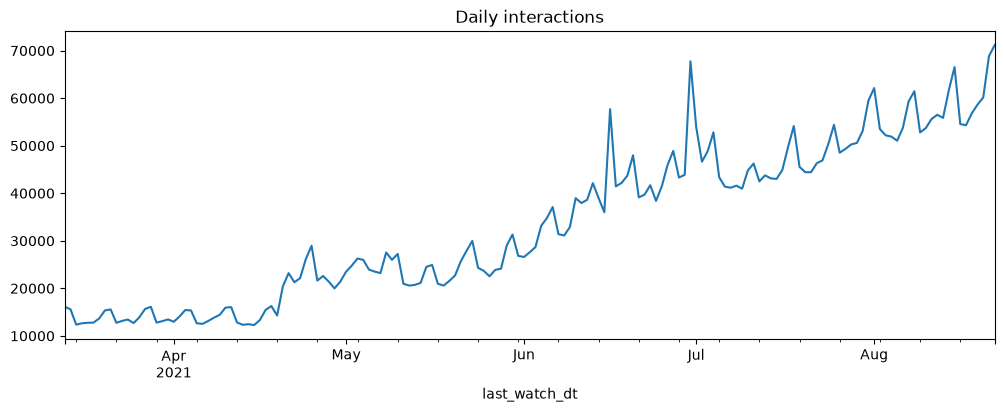

In [12]:
daily_interactions = interactions.groupby("last_watch_dt").size()
daily_interactions.plot(figsize=(12, 4), title="Daily interactions")

<Axes: title={'center': 'Daily active users'}, xlabel='last_watch_dt'>

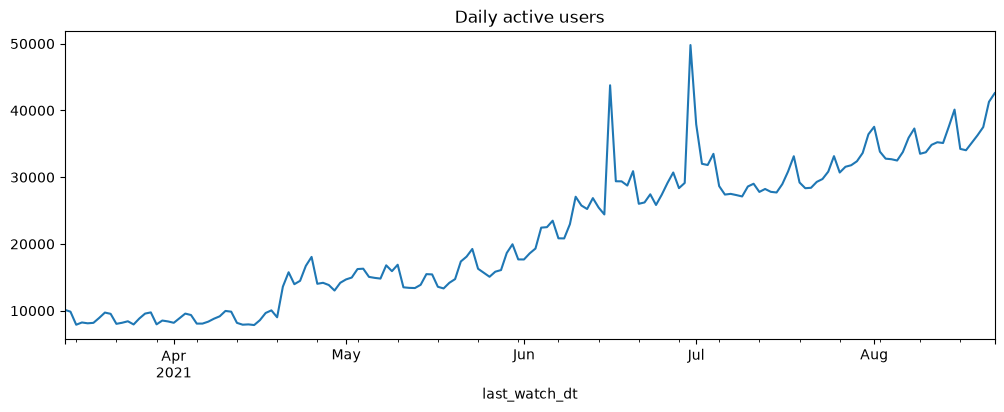

In [13]:
daily_users = interactions.groupby("last_watch_dt")["user_id"].nunique()
daily_users.plot(figsize=(12, 4), title="Daily active users")

<Axes: title={'center': 'New users per day'}, xlabel='last_watch_dt'>

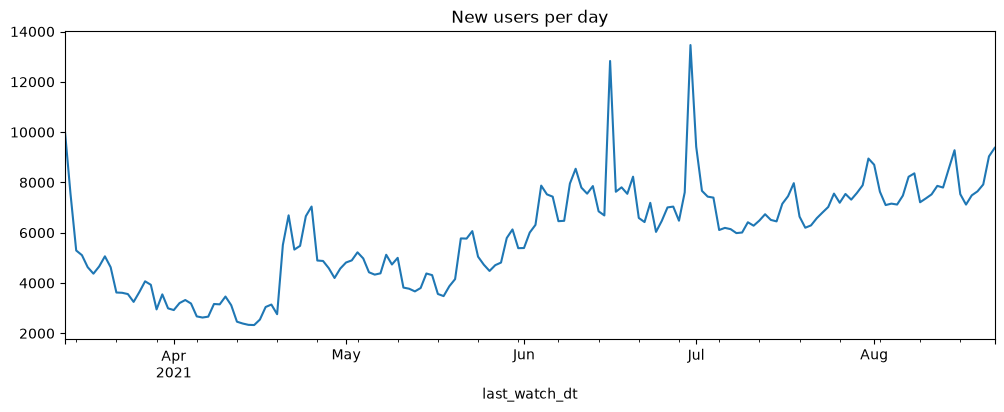

In [14]:
first_seen = interactions.groupby("user_id")["last_watch_dt"].min()
new_users = first_seen.value_counts().sort_index()
new_users.plot(figsize=(12, 4), title="New users per day")

<Axes: title={'center': 'Daily interactions per active user'}, xlabel='last_watch_dt'>

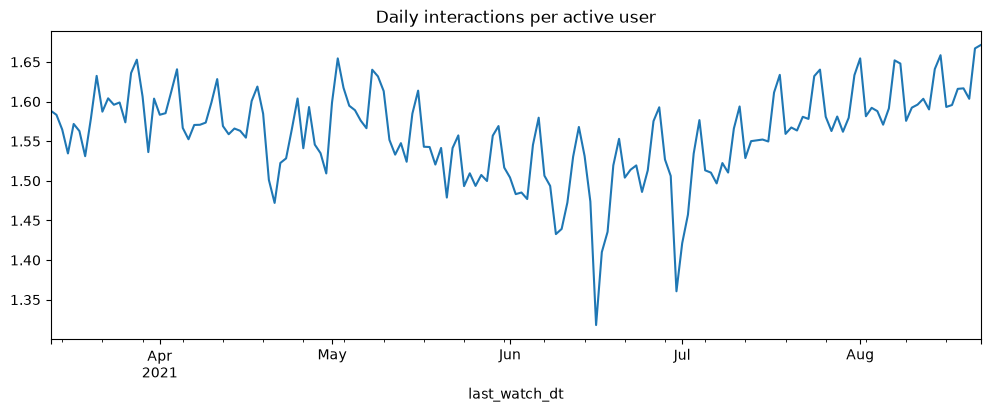

In [15]:
interactions_per_user = daily_interactions / daily_users
interactions_per_user.plot(figsize=(12, 4), title="Daily interactions per active user")

<Axes: title={'center': 'Average daily interactions by weekday'}>

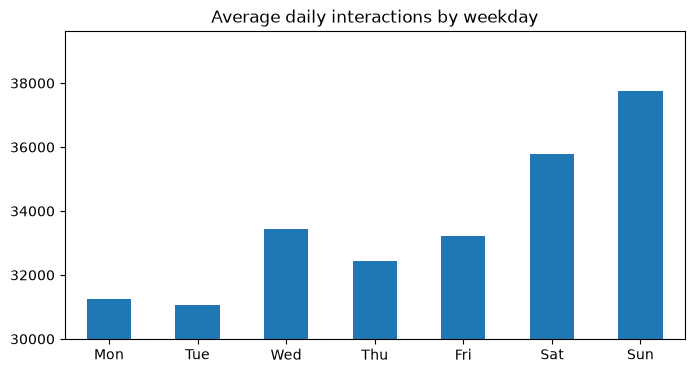

In [16]:
weekday_activity = daily_interactions.groupby(
    daily_interactions.index.dayofweek
).mean()
weekday_activity.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

weekday_activity.plot.bar(
    figsize=(8, 4),
    title="Average daily interactions by weekday",
    rot=0,
    ylim=(30000, None)
)

In [17]:
user_activity = interactions.groupby("user_id").size()
user_activity.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

count    962179.000000
mean          5.691510
std          10.886262
min           1.000000
50%           2.000000
75%           6.000000
90%          13.000000
95%          21.000000
99%          49.000000
max        1341.000000
dtype: float64

<Axes: >

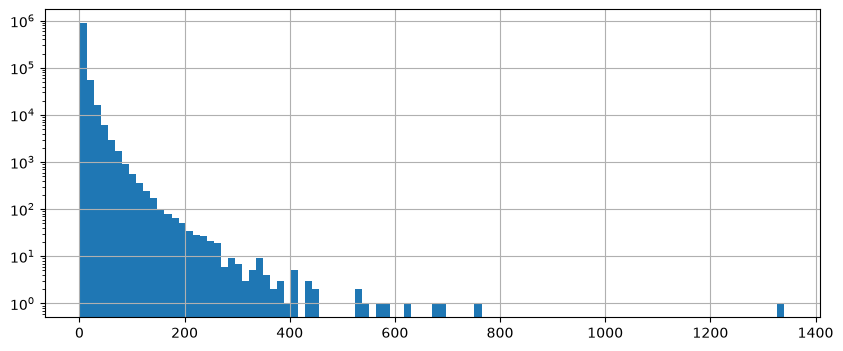

In [18]:
user_activity.hist(bins=100, figsize=(10, 4), log=True)

In [19]:
user_activity.nlargest(10)

user_id
416206     1341
1010539     764
555233      685
11526       676
409259      625
1057189     579
400913      575
473766      545
230644      529
559162      524
dtype: int64

In [20]:
item_popularity = interactions.groupby("item_id").size()

item_popularity.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

count     15706.000000
mean        348.672546
std        3194.053580
min           1.000000
50%          12.000000
75%          99.000000
90%         606.000000
95%        1313.500000
99%        4687.700000
max      202457.000000
dtype: float64

<Axes: >

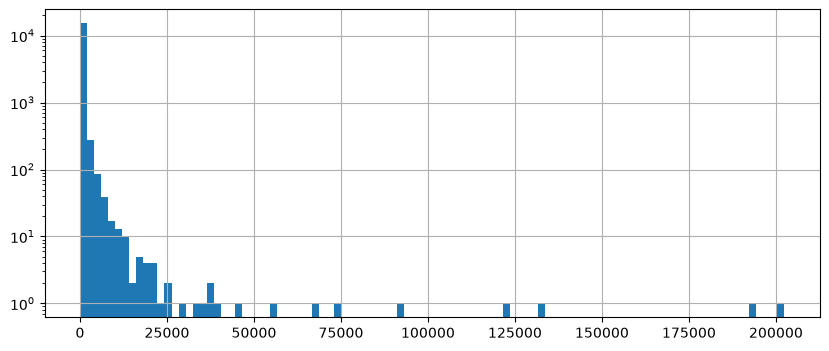

In [21]:
item_popularity.hist(bins=100, figsize=(10, 4), log=True)

In [22]:
items.set_index("item_id").loc[
    item_popularity.nlargest(10).index,
    ["title", "genres"]
].assign(views=item_popularity.nlargest(10))

,title,genres,views
item_id,,,
10440,Хрустальный,"триллеры, детективы",202457
15297,Клиника счастья,"драмы, мелодрамы",193123
9728,Гнев человеческий,"боевики, триллеры",132865
13865,Девятаев,"драмы, военные, приключения",122119
4151,Секреты семейной жизни,комедии,91167
3734,Прабабушка легкого поведения,комедии,74803
2657,Подслушано,"драмы, триллеры",68581
4880,Афера,комедии,55043
142,Маша,"драмы, триллеры",45367


<Axes: xlabel='last_watch_dt'>

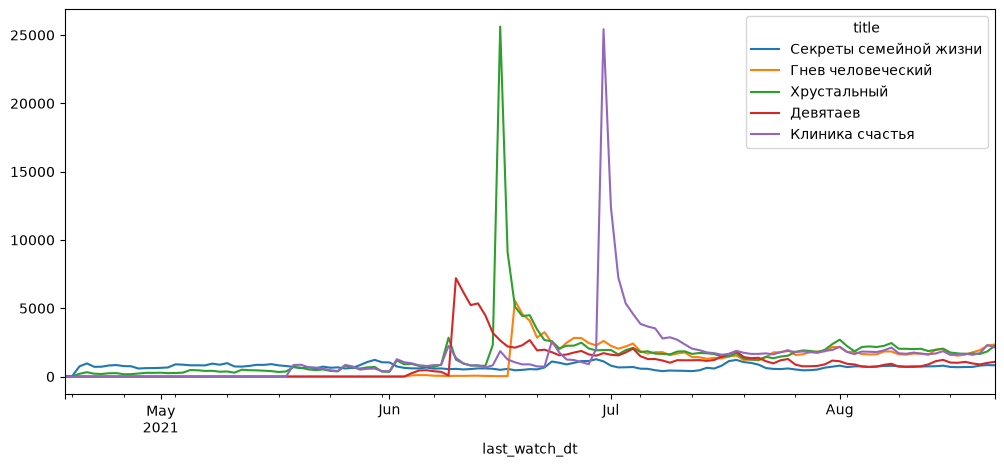

In [23]:
top_items = item_popularity.nlargest(5).index

top_item_activity = (
    interactions[interactions["item_id"].isin(top_items)]
    .groupby(["last_watch_dt", "item_id"])
    .size()
    .unstack(fill_value=0)
)

top_item_activity.columns = items.set_index("item_id").loc[
    top_item_activity.columns, "title"
]

top_item_activity.plot(figsize=(12, 5))

Графики для сериалов "Хрустальный" и "Клиника счастья" выглядят подозрительно, но их пиковые значения приходятся именно на дату выхода их последних серий, вероятно, в этот день рекомендательные системы сервиса специально пушили сериалы в рекомендации абсолютно всем пользователям без оглядки на их предпочтения, а также активно рекламировали проекты в честь финалов проектов. 

In [24]:
for pct in [0.01, 0.05, 0.10]:
    n = round(len(item_popularity) * pct)
    share = item_popularity.nlargest(n).sum() / item_popularity.sum()
    print(f"Top {pct:.0%} items: {share:.1%} interactions")

Top 1% items: 45.6% interactions
Top 5% items: 72.4% interactions
Top 10% items: 85.0% interactions


In [25]:
interactions["watched_pct"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

count    5.475423e+06
mean     4.637400e+01
std      4.191853e+01
min      0.000000e+00
10%      0.000000e+00
25%      4.000000e+00
50%      3.200000e+01
75%      1.000000e+02
90%      1.000000e+02
95%      1.000000e+02
99%      1.000000e+02
max      1.000000e+02
Name: watched_pct, dtype: float64

<Axes: >

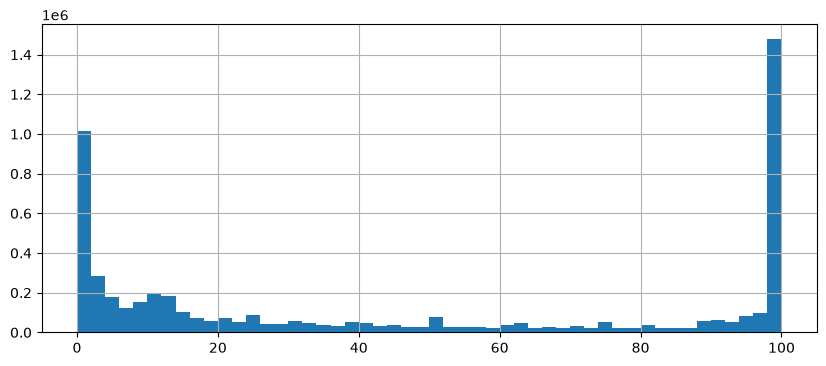

In [26]:
interactions["watched_pct"].hist(
    bins=50,
    figsize=(10, 4)
)

<Axes: title={'center': 'Crystal: median watch duration by day'}, xlabel='last_watch_dt'>

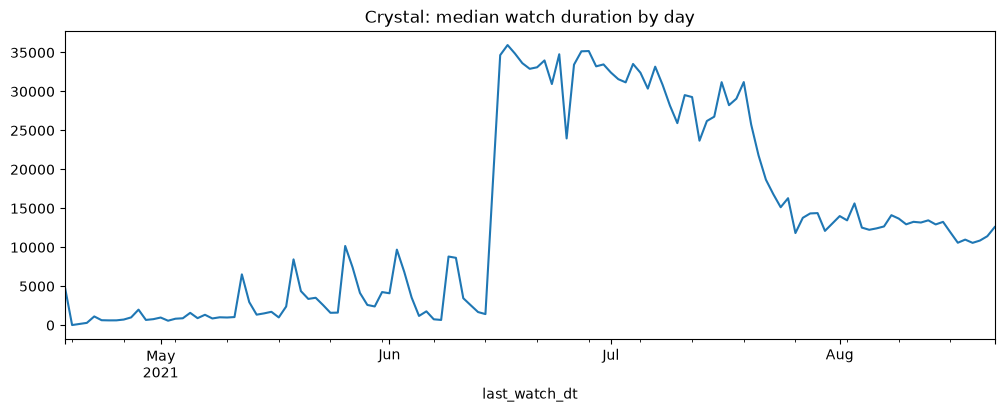

In [27]:
crystal = interactions[interactions["item_id"] == 10440]

crystal.groupby("last_watch_dt")["total_dur"].median().plot(
    figsize=(12, 4),
    title="Crystal: median watch duration by day"
)

<Axes: title={'center': 'Crystal: median watched percentage by day'}, xlabel='last_watch_dt'>

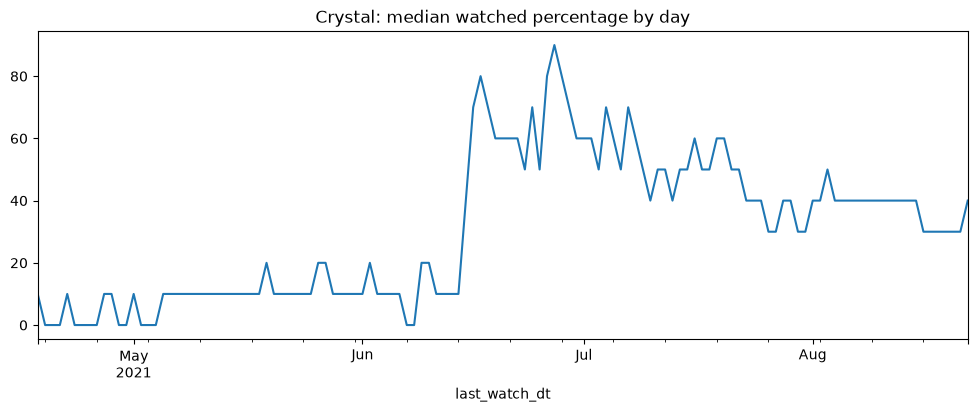

In [28]:
crystal.groupby("last_watch_dt")["watched_pct"].median().plot(
    figsize=(12, 4),
    title="Crystal: median watched percentage by day"
)

In [29]:
top_two = item_popularity.nlargest(2).index

print("Share of interactions:", item_popularity.loc[top_two].sum() / len(interactions))

print(
    "Median watched_pct (all):",
    interactions["watched_pct"].median()
)

print(
    "Median watched_pct (without top 2):",
    interactions.loc[
        ~interactions["item_id"].isin(top_two), "watched_pct"
    ].median()
)

Share of interactions: 0.07223554946623155
Median watched_pct (all): 32.0
Median watched_pct (without top 2): 31.0


In [30]:
interactions["total_dur"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

count    5.476251e+06
mean     8.295490e+03
std      4.856799e+04
min      1.000000e+00
10%      4.200000e+01
25%      3.710000e+02
50%      2.898000e+03
75%      7.116000e+03
90%      1.511200e+04
95%      3.144500e+04
99%      9.008300e+04
max      8.041167e+07
Name: total_dur, dtype: float64

<Axes: >

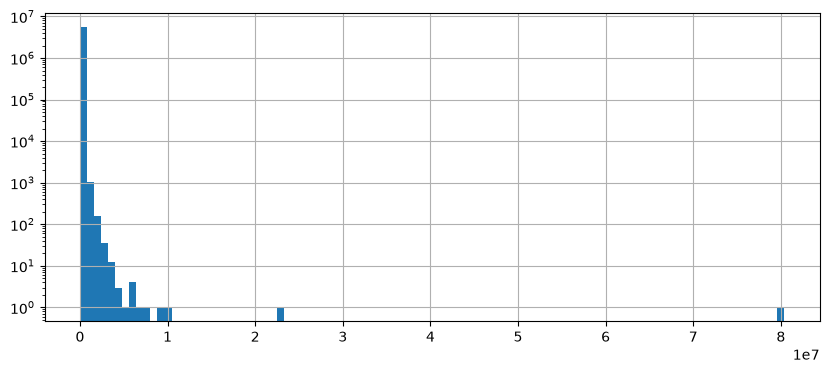

In [31]:
interactions["total_dur"].hist(
    bins=100,
    figsize=(10, 4),
    log=True
)

In [32]:
interactions.nlargest(10, "total_dur").merge(
    items[["item_id", "title", "content_type"]],
    on="item_id"
)

,user_id,item_id,last_watch_dt,total_dur,watched_pct,title,content_type
0,80682,874,2021-08-01,80411672,100.0,Буренка Даша,series
1,546906,8157,2021-07-29,23007956,99.0,Смешарики,series
2,696597,4331,2021-08-17,9731102,100.0,Оранжевая корова,series
3,345987,6968,2021-05-25,9026441,100.0,Гримм,series
4,78911,14120,2021-08-14,7241091,100.0,Маша и Медведь,series
5,801503,7590,2021-08-11,6959397,90.0,Черепашки-ниндзя,series
6,797869,7061,2021-05-30,6147245,63.0,Как устроена Вселенная,series
7,47224,5533,2021-05-30,5794161,100.0,Титаник,film
8,843846,11661,2021-04-28,5748938,100.0,Презумпция виновности,film
9,383409,496,2021-07-16,5674805,65.0,Воскресший Эртугрул,series


Значения в 931 и 266 суток времени просмотра выглядят как ошибка или выброс, особенно, странно они выглядят, учитывая, что в целом данные только за 163 дня представлены. С другой стороны, это могут быть какие-то крайне преданные зрители МТС ТВ, которых тоже учитывали в статистике. А мы в целом видим, что статистика в датасете ведется ещё с МТС ТВ, так как KION как проект стартовал только 20 апреля 2021 (это кстати видно на всех графиках), а первые наблюдения в датасете от 18 марта 2021. 

In [33]:
items[["title", "genres", "actors", "directors"]].head(10)

,title,genres,actors,directors
0,Поговори с ней,"драмы, зарубежные, детективы, мелодрамы","Адольфо Фернандес, Ана Фернандес, Дарио Гранди...",Педро Альмодовар
1,Голые перцы,"зарубежные, приключения, комедии","Адам Палли, Брайан Хаски, Дж.Б. Смув, Джейсон ...",Скот Армстронг
2,Тактическая сила,"криминал, зарубежные, триллеры, боевики, комедии","Адриан Холмс, Даррен Шалави, Джерри Вассерман,...",Адам П. Калтраро
3,45 лет,"драмы, зарубежные, мелодрамы","Александра Риддлстон-Барретт, Джеральдин Джейм...",Эндрю Хэй
4,Все решает мгновение,"драмы, спорт, советские, мелодрамы","Александр Абдулов, Александр Демьяненко, Алекс...",Виктор Садовский
5,Северо-Юг,"драмы, русские","Алексей Воронин, Алексей Мурашов, Алена Алинин...",Юрий Грубник
6,Марья-искусница,"фильмы, сказки, приключения, советские, семейн...","Александр Баранов, Александр Хвыля, Анатолий К...",Александр Роу
7,Принцесса Лебедь: Пират или принцесса,"для детей, сказки, полнометражные, зарубежные,...","Брайан Ниссен, Гарднер Джаэс, Грант Дураззо, Д...",Ричард Рич
8,Лабиринты прошлого,"криминал, детективы, драмы, зарубежные, триллеры","Барбара Ленни, Инма Куэста, Карла Кампра, Пене...",Асгар Фархади
9,Третья попытка,"русские, мелодрамы","Александр Асташенок, Александр Пашков, Андрей ...",Игорь Мужжухин


In [34]:
items[["genres", "actors", "directors"]].isna().mean().mul(100).round(1)

genres        0.0
actors       16.4
directors     9.5
dtype: float64

In [35]:
for col in ["genres", "actors", "directors"]:
    items[f"{col}_list"] = items[col].fillna("").str.split(", ")

In [36]:
for col in ["genres", "actors", "directors"]:
    values = items[f"{col}_list"].explode()
    print(col, values[values != ""].nunique())

genres 95
actors 61887
directors 8839


In [37]:
items[["genres_list", "actors_list", "directors_list"]].map(
    lambda x: len([v for v in x if v])
).describe()

,genres_list,actors_list,directors_list
count,15963.000000,15963.000000,15963.000000
mean,2.545699,8.755685,1.115830
std,1.336912,8.506736,0.809465
min,1.000000,0.000000,0.000000
25%,1.000000,4.000000,1.000000
50%,2.000000,10.000000,1.000000
75%,3.000000,10.000000,1.000000
max,9.000000,369.000000,21.000000


In [38]:
actor_counts = items["actors_list"].explode().value_counts()
actor_counts

actors_list
                     2619
Николас Кейдж          59
Сергей Никоненко       58
Армен Джигарханян      55
Лев Дуров              54
                     ... 
Дэйн Уайт О’Хара        1
Томас Кэйн-Бирн         1
Джудит Родди            1
Джимми Смоллхорн        1
Мкртыч Арзуманян        1
Name: count, Length: 61888, dtype: int64

In [39]:
actor_counts.describe()

count    61888.000000
mean         2.300704
std         11.044988
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       2619.000000
Name: count, dtype: float64

In [40]:
actor_counts = actor_counts.drop("")
(actor_counts >= 2).mean()

np.float64(0.34285067946418474)

In [41]:
director_counts = items["directors_list"].explode().value_counts().drop("")
director_counts

directors_list
Оливье Шиабоду     511
Денис Марти         58
Денис Франческо     49
Антонио Адамо       44
Кови                40
                  ... 
А. Хван              1
Эшреф Рейбрук        1
Эрик Эгер            1
Марк О’Коннор        1
Михаил Миронов       1
Name: count, Length: 8839, dtype: int64

In [42]:
director_counts.describe()

count    8839.000000
mean        2.015160
std         5.893795
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       511.000000
Name: count, dtype: float64

In [43]:
(director_counts >= 2).mean()

np.float64(0.3637289286118339)

In [44]:
from scipy.sparse import coo_matrix

user_ids = pd.factorize(interactions["user_id"])[0]
item_ids = pd.factorize(interactions["item_id"])[0]

user_item = coo_matrix(
    (pd.Series(1, index=interactions.index), (user_ids, item_ids)),
    shape=(interactions["user_id"].nunique(), interactions["item_id"].nunique())
).tocsr()
user_item.shape

(962179, 15706)

In [45]:
from scipy.sparse import bmat
from scipy.sparse.csgraph import connected_components

graph = bmat([
    [None, user_item],
    [user_item.T, None]
], format="csr")

n_components, labels = connected_components(graph, directed=False)

In [46]:
import numpy as np

component_sizes = np.bincount(labels)
print("Number of components:", n_components)
print("Largest component:", component_sizes.max())
print("Share in largest component:", component_sizes.max() / graph.shape[0])

Number of components: 73
Largest component: 977737
Share in largest component: 0.9998486529602152


In [52]:
fold_starts = pd.date_range(
    "2021-06-21",
    "2021-08-09",
    freq="7D"
)

fold_ends = fold_starts + pd.Timedelta(days=7)

In [57]:
for start, end in zip(fold_starts, fold_ends):
    history = interactions[interactions["last_watch_dt"] < start]
    future = interactions[
        (interactions["last_watch_dt"] >= start) &
        (interactions["last_watch_dt"] < end)
    ]

    warm_users = future["user_id"].isin(history["user_id"])

    print(start.date(), f"{warm_users.mean():.1%}")
    

2021-06-21 68.8%
2021-06-28 68.3%
2021-07-05 72.3%
2021-07-12 68.5%
2021-07-19 70.5%
2021-07-26 69.0%
2021-08-02 70.8%
2021-08-09 71.6%


In [58]:
for start, end in zip(fold_starts, fold_ends):
    history = interactions[interactions["last_watch_dt"] < start]
    future = interactions[
        (interactions["last_watch_dt"] >= start) &
        (interactions["last_watch_dt"] < end)
    ]

    warm_items = future["item_id"].isin(history["item_id"])

    print(start.date(), f"{warm_items.mean():.1%}")

2021-06-21 92.1%
2021-06-28 97.8%
2021-07-05 94.5%
2021-07-12 98.1%
2021-07-19 98.5%
2021-07-26 98.6%
2021-08-02 97.0%
2021-08-09 96.1%


Для обучения я планирую использовать time series cross-validation, для этого важно понимать какое у фолдов покрытие пользователей и фильмов, особенно, для графовых методов. Как мы видим, приличную долю от всех заимодействий за неделю совершают новые пользователи без истории, около 30%. Я хочу сосредоточить свою работу именно на удержании старых пользователей, для которых есть история, а cold-start оставить как отдельную задачу. 